## Predictive Maintenance for Industrial Equipment using Machine Learning

# Table of Contents

1. Problem Statement
2. Dataset Understanding
3. Exploratory Data Analysis
4. Data Preprocessing
5. Model Building
6. Model Comparison
7. Feature Importance
8. Hyperparameter Tuning
9. Model Persistence
10. Project Conclusion

## 1. Problem Statement

Unexpected machine failures in industrial environments lead to production downtime, increased maintenance costs, and safety risks.

The objective of this project is to develop a machine learning model that predicts whether a machine is likely to fail based on operational and sensor measurements. By identifying potential failures in advance, maintenance can be scheduled proactively, reducing downtime and improving operational efficiency.

In [115]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Display all dataframe columns
pd.set_option("display.max_columns", None)

## 2. Dataset Understanding

In [116]:
df = pd.read_csv("ai4i2020.csv")

In [117]:
print("Shape of Dataset:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Shape of Dataset: (10000, 14)

Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [118]:
display(df.head())

display(df.tail())

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [119]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [120]:
display(df.describe())

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [121]:
display(df.describe(include = "object"))

,Product ID,Type
count,10000,10000
unique,10000,3
top,L57163,L
freq,1,6000


In [122]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum()/len(df))*100
})

display(missing)

,Missing Values,Percentage
UDI,0,0.0
Product ID,0,0.0
Type,0,0.0
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Machine failure,0,0.0
TWF,0,0.0


In [123]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [124]:
print("Data Types:")
display(df.dtypes)

print("\nNumber of Unique Values:")
display(df.nunique())

Data Types:


,0
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64



Number of Unique Values:


,0
UDI,10000
Product ID,10000
Type,3
Air temperature [K],93
Process temperature [K],82
Rotational speed [rpm],941
Torque [Nm],577
Tool wear [min],246
Machine failure,2
TWF,2


The AI4I 2020 Predictive Maintenance Dataset contains operational data collected from industrial machines.

Each record represents the operating condition of a machine at a specific point in time.

The dataset contains:
- Machine information
- Sensor measurements
- Operating conditions
- Machine failure status

The objective is to predict whether a machine will fail based on these operational measurements.

# 3. Exploratory Data Analysis (EDA)

The objective of Exploratory Data Analysis (EDA) is to understand the underlying patterns, distributions, and relationships within the dataset before model development.

During this stage, we will:

- Analyze the target variable distribution
- Explore categorical features
- Study numerical feature distributions
- Identify outliers
- Examine feature correlations
- Compare feature distributions with respect to machine failures

In [125]:
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

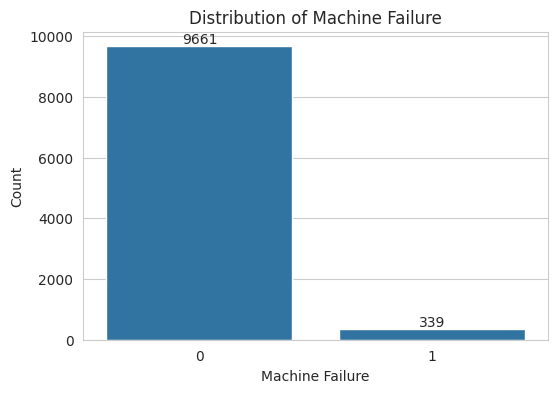

In [126]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Distribution of Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Count")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [127]:
failure_percentage = (
    df["Machine failure"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(failure_percentage)

,proportion
Machine failure,
0,96.61
1,3.39


### Observation

The target variable is highly imbalanced.

Most observations belong to the **non-failure** class, while only a small percentage correspond to machine failures.

During model evaluation, relying solely on accuracy may be misleading. Therefore, metrics such as Precision, Recall, F1-score, and ROC-AUC will be used to evaluate model performance.

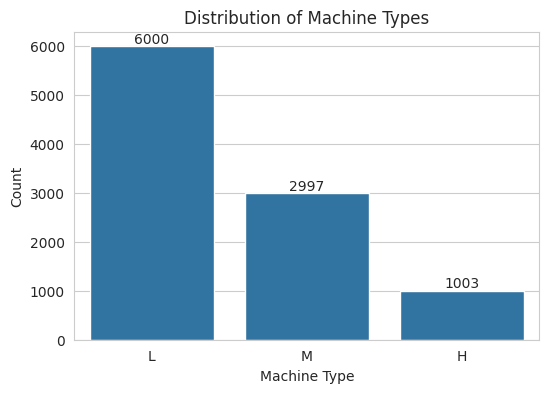

In [128]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    data=df,
    x="Type",
    order=df["Type"].value_counts().index
)

plt.title("Distribution of Machine Types")
plt.xlabel("Machine Type")
plt.ylabel("Count")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

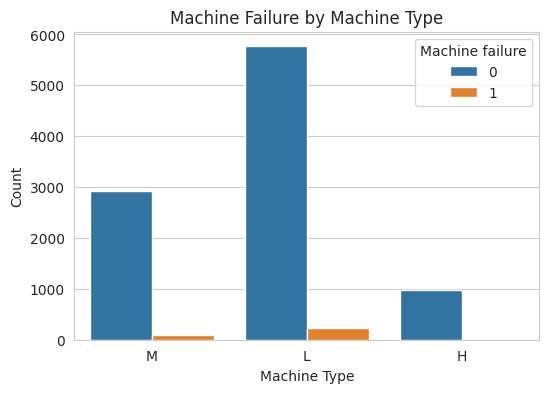

In [129]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    data=df,
    x="Type",
    hue="Machine failure"
)

plt.title("Machine Failure by Machine Type")
plt.xlabel("Machine Type")
plt.ylabel("Count")

plt.show()

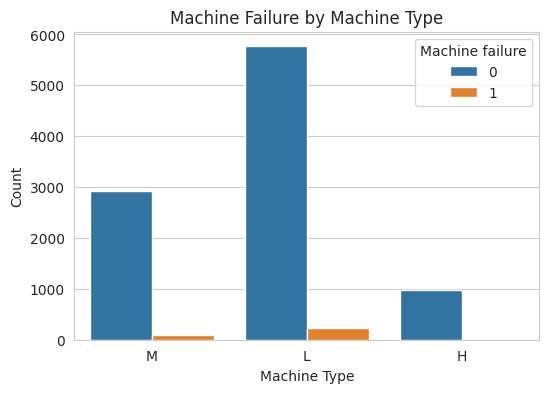

In [130]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    data=df,
    x="Type",
    hue="Machine failure"
)

plt.title("Machine Failure by Machine Type")
plt.xlabel("Machine Type")
plt.ylabel("Count")

plt.show()

### Observation

- The dataset contains **9,661 non-failure** instances and **339 failure** instances, indicating that only **3.39%** of the observations correspond to machine failures. This shows that the target variable is **highly imbalanced**.
- The machine population is also unevenly distributed across quality types, with **Low-quality (L)** machines accounting for **6,000** samples, followed by **Medium-quality (M)** with **2,997** samples and **High-quality (H)** with **1,003** samples.
- Most failure cases are observed in **Low-quality (L)** machines; however, this is expected because they constitute the largest portion of the dataset. Therefore, raw failure counts alone cannot be used to conclude that L machines are more prone to failure. A comparison based on **failure rates** will provide a more meaningful assessment.
- Due to the class imbalance, model performance will be evaluated using **Precision, Recall, F1-score, and ROC-AUC**, in addition to Accuracy.

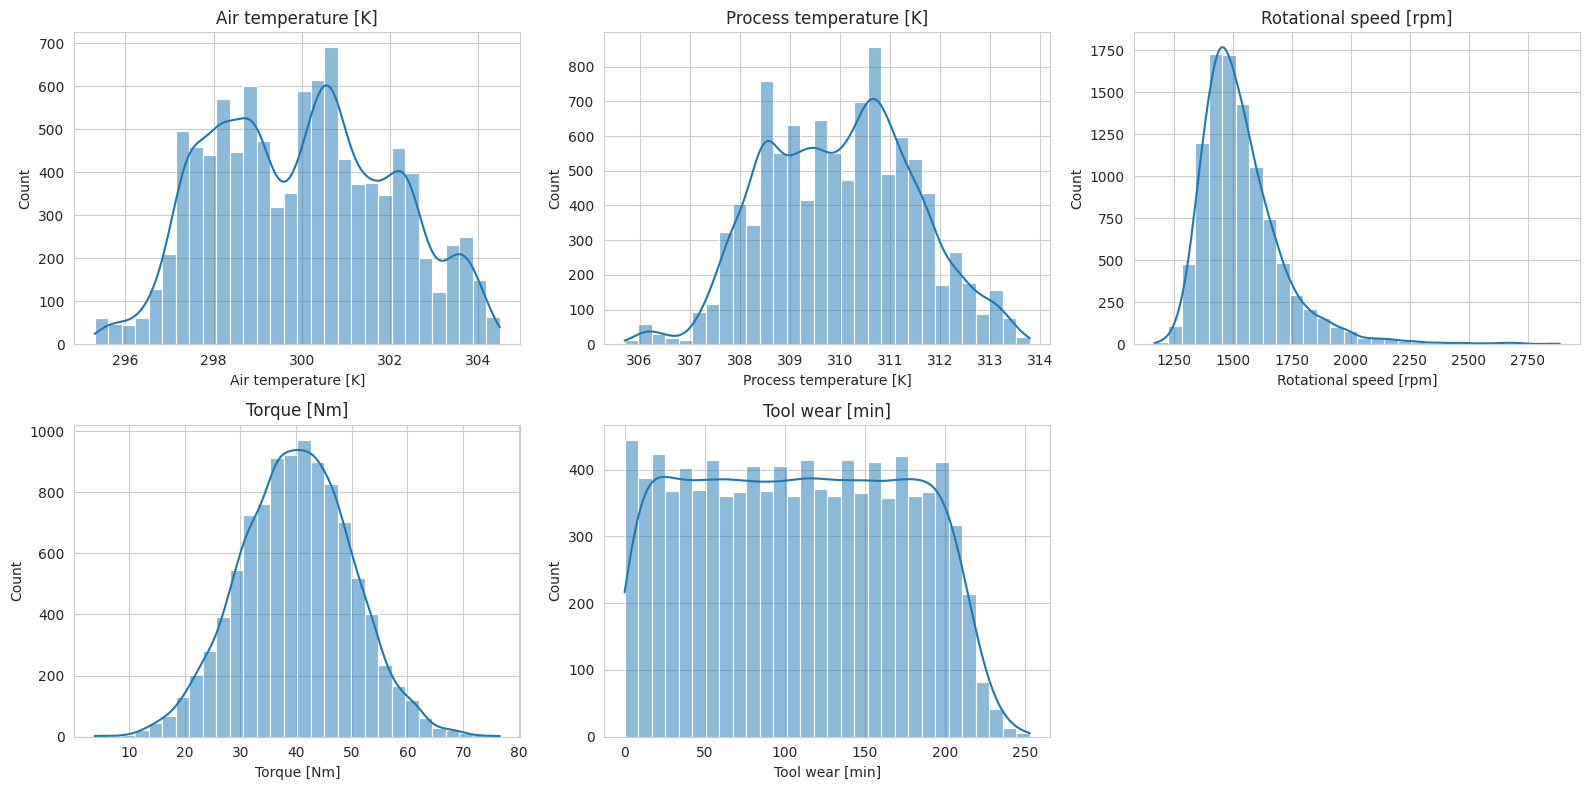

In [131]:
numerical_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    sns.histplot(df[feature], kde=True, bins=30, ax=axes[i])
    axes[i].set_title(feature)

fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

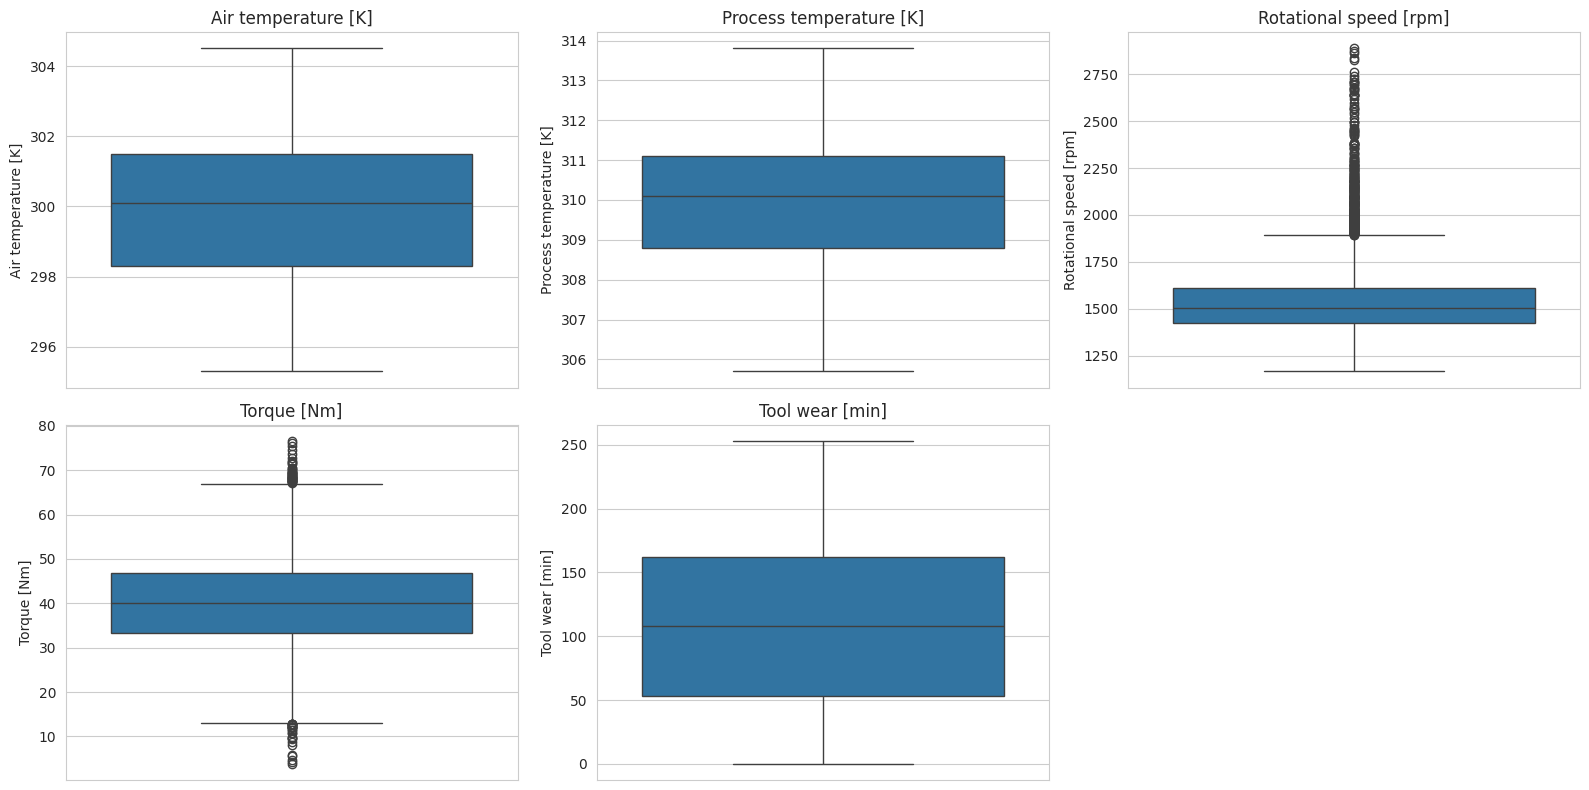

In [132]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    sns.boxplot(y=df[feature], ax=axes[i])
    axes[i].set_title(feature)

fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

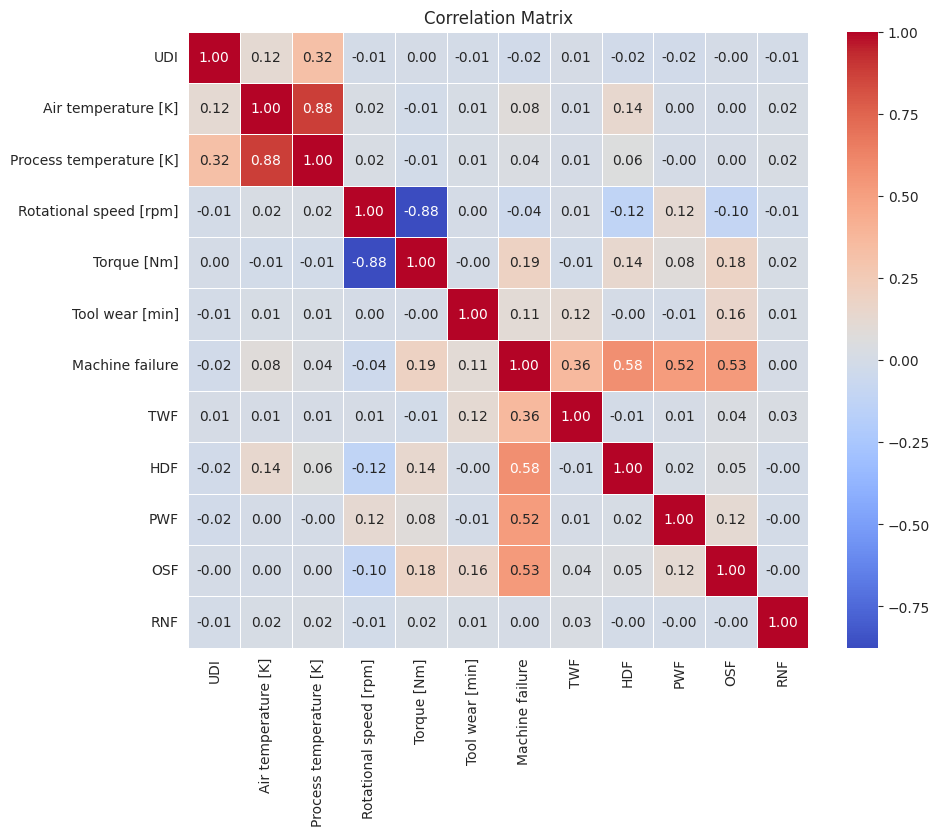

In [133]:
plt.figure(figsize=(10,8))

corr = df.drop(columns=["Product ID","Type"]).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

### Observation

- **Air Temperature** and **Process Temperature** exhibit a strong positive correlation (**0.88**), indicating that these variables increase together during machine operation.
- **Rotational Speed** and **Torque** show a strong negative correlation (**-0.88**), suggesting that machines operating at higher rotational speeds generally experience lower torque.
- Most numerical features have only weak correlations with the target variable (**Machine failure**), indicating that machine failure is influenced by a combination of multiple operating conditions rather than a single feature.
- The failure-specific variables (**TWF, HDF, PWF, OSF, RNF**) show moderate correlations with the target because they represent different types of machine failures. These variables will be removed during preprocessing to prevent **data leakage**, as they directly describe the failure outcome.
- Apart from the expected relationships between temperature variables and between rotational speed and torque, no severe multicollinearity is observed among the predictor features.

## Numerical Features by Machine Failure

Comparing numerical feature distributions across failure and non-failure classes helps identify operational characteristics associated with machine failures and provides insight into the predictive capability of each feature.

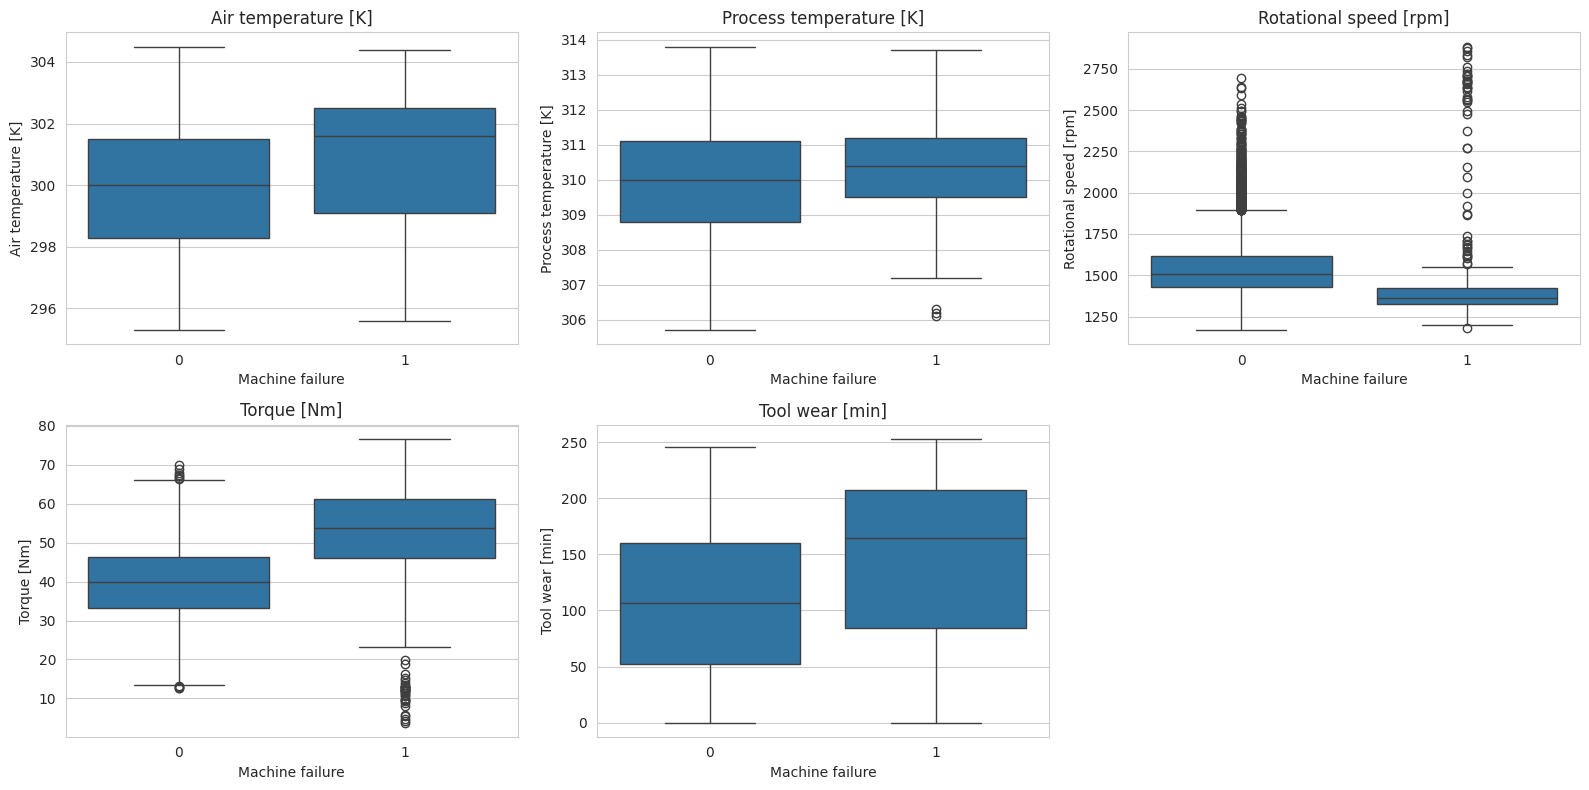

In [134]:
numerical_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    sns.boxplot(
        data=df,
        x='Machine failure',
        y=feature,
        ax=axes[i]
    )
    axes[i].set_title(feature)

# Remove the unused subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

### Observation

- Machines that experienced failure generally operate at **higher air temperatures** and **higher process temperatures** than non-failure machines.
- Failed machines tend to have **lower rotational speeds** while exhibiting **higher torque**, suggesting that increased mechanical load may contribute to failures.
- **Tool wear** is noticeably higher for failed machines, indicating that increased tool usage is associated with a greater likelihood of machine failure.
- The separation between failure and non-failure distributions is most evident for **Torque** and **Tool Wear**, suggesting that these features may be strong predictors of machine failure.
- Although some overlap exists between the two classes, the observed differences indicate that a combination of operational and sensor measurements can effectively support predictive maintenance models.

# EDA Summary

The exploratory data analysis revealed several important characteristics of the dataset:

- The dataset contains **10,000 observations** with **no missing values** or **duplicate records**, indicating high data quality.
- The target variable is **highly imbalanced**, with only **3.39%** of observations corresponding to machine failures.
- Low-quality (L) machines constitute the largest proportion of the dataset, followed by Medium (M) and High (H) machines.
- Air temperature and process temperature are strongly positively correlated, while rotational speed and torque exhibit a strong negative correlation.
- Valid operational outliers are present in rotational speed and torque; these will be retained as they represent genuine machine behavior rather than data errors.
- Failed machines generally operate under **higher temperatures**, **higher torque**, **greater tool wear**, and **lower rotational speeds**, indicating that these variables are likely to be informative predictors of machine failure.

# 4. Data Preprocessing

The objective of this stage is to prepare the dataset for machine learning by removing irrelevant features, preventing data leakage, encoding categorical variables, and splitting the data into training and testing sets.

In [135]:
df_model = df.drop(
    columns=[
        'UDI',
        'Product ID',
        'TWF',
        'HDF',
        'PWF',
        'OSF',
        'RNF'
    ]
)

df_model.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


### Observation

- The identifier columns (`UDI` and `Product ID`) were removed because they do not contribute to predicting machine failure.
- The failure-type columns (`TWF`, `HDF`, `PWF`, `OSF`, and `RNF`) were removed to prevent **data leakage**, as they directly indicate the cause of machine failure.
- The remaining features represent the operational characteristics of the machines and will be used for model training.

In [136]:
df_model = pd.get_dummies(
    df_model,
    columns=['Type'],
    drop_first=True,
    dtype=int
)

df_model.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,0,1
1,298.2,308.7,1408,46.3,3,0,1,0
2,298.1,308.5,1498,49.4,5,0,1,0
3,298.2,308.6,1433,39.5,7,0,1,0
4,298.2,308.7,1408,40.0,9,0,1,0


### Observation

The categorical feature **Type** was converted into numerical dummy variables using One-Hot Encoding.

One-Hot Encoding enables machine learning algorithms to process categorical data without assuming any ordinal relationship between machine types.

In [137]:
X = df_model.drop('Machine failure', axis=1)
y = df_model['Machine failure']

print("Feature Matrix Shape :", X.shape)
print("Target Vector Shape :", y.shape)

Feature Matrix Shape : (10000, 7)
Target Vector Shape : (10000,)


## Train-Test Split

The dataset is divided into training and testing sets using **stratified sampling**. This ensures that the proportion of failure and non-failure observations is maintained in both subsets, providing a representative evaluation of model performance.

In [138]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [139]:
print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)

print("Training Labels   :", y_train.shape)
print("Testing Labels    :", y_test.shape)

Training Features : (8000, 7)
Testing Features  : (2000, 7)
Training Labels   : (8000,)
Testing Labels    : (2000,)


In [140]:
print("Training Set:")
display(y_train.value_counts(normalize=True).rename("Proportion"))

print("\nTesting Set:")
display(y_test.value_counts(normalize=True).rename("Proportion"))

Training Set:


,Proportion
Machine failure,
0,0.966125
1,0.033875



Testing Set:


,Proportion
Machine failure,
0,0.966
1,0.034


## Feature Scaling

Feature scaling standardizes numerical features by transforming them to have a mean of 0 and a standard deviation of 1.

Scaling is applied for algorithms such as Logistic Regression, while tree-based models are trained using the original feature values.

In [141]:
from sklearn.preprocessing import StandardScaler
numerical_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]
scaler = StandardScaler()


X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()


X_train_scaled[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

X_test_scaled[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

In [142]:
X_train_scaled.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M
4058,0.998914,0.604282,-0.460607,0.718305,-0.843997,0,1
1221,-1.505194,-1.153260,-0.775574,0.638456,0.382263,0,1
6895,0.498092,1.077466,-1.007654,0.558607,0.460870,0,1
9863,-0.553633,-0.139294,-0.709265,1.626586,-0.372359,1,0
8711,-1.455112,-1.018064,1.070019,-1.128202,-0.906882,1,0


# 5. Model Building

In this stage, multiple classification algorithms are trained and evaluated to predict machine failures.

The following models will be compared:

- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost

Each model will be evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

In [143]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [144]:
def evaluate_model(model, X_train, X_test, y_train, y_test):
    # Train the model
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Metrics
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    return metrics, y_pred

In [145]:
log_reg = LogisticRegression(
    random_state=42,
    class_weight='balanced'
)

log_metrics, log_pred = evaluate_model(
    log_reg,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

pd.DataFrame(log_metrics, index=["Logistic Regression"])

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.8245,0.141772,0.823529,0.241901,0.906916


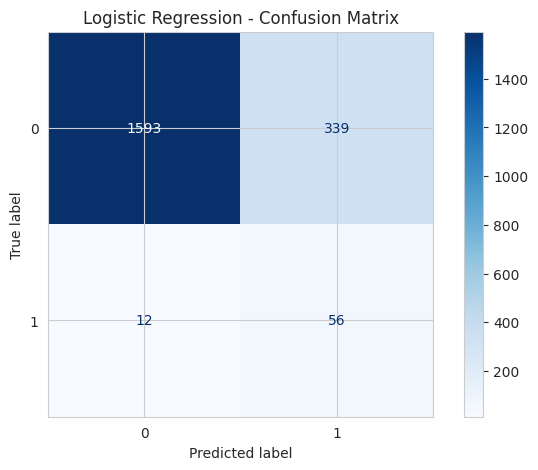

In [146]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    log_pred,
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

### Observation

- Logistic Regression achieved a high **Accuracy (96.75%)**; however, this is largely influenced by the severe class imbalance in the dataset.
- The model correctly identified **1928** non-failure instances but detected only **7** out of **68** actual failure cases.
- The **Recall (10.29%)** is very low, indicating that the model misses a large proportion of machine failures.
- Although the **Precision (63.64%)** is reasonably good, the low Recall results in a poor **F1-score (17.72%)**.
- The **ROC-AUC (89.95%)** suggests that the model has good ranking ability, but its default classification threshold is not suitable for detecting the minority failure class.
- Overall, Logistic Regression serves as a useful baseline model, but more powerful ensemble methods are expected to achieve better failure detection.

In [147]:
decision_tree = DecisionTreeClassifier(
    random_state=42
)

dt_metrics, dt_pred = evaluate_model(
    decision_tree,
    X_train,
    X_test,
    y_train,
    y_test
)

pd.DataFrame(dt_metrics, index=["Decision Tree"])

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Decision Tree,0.978,0.681818,0.661765,0.671642,0.825448


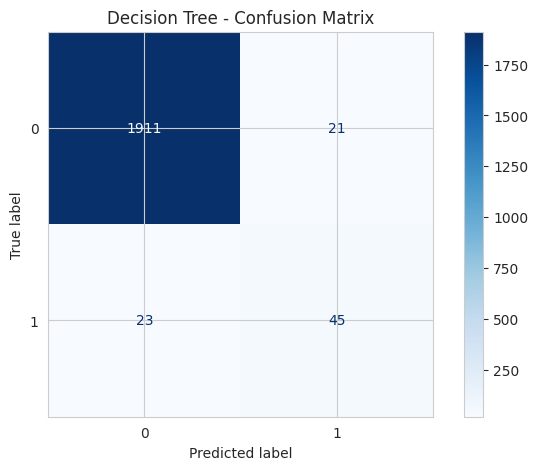

In [148]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred,
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [149]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_metrics, rf_pred = evaluate_model(
    random_forest,
    X_train,
    X_test,
    y_train,
    y_test
)

pd.DataFrame(rf_metrics, index=["Random Forest"])

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Random Forest,0.9815,0.878049,0.529412,0.66055,0.961599


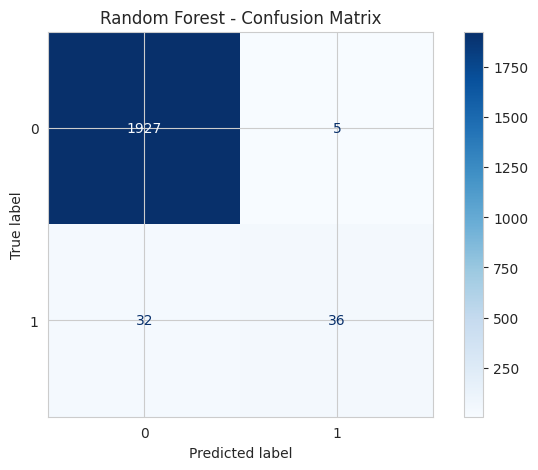

In [150]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

### Observation

- The Random Forest model achieved the **highest Accuracy (98.15%)** among the models evaluated so far.
- It correctly identified **36 out of 68** failure cases while producing only **5 false positives**, resulting in a high **Precision (87.80%)**.
- Compared with the Decision Tree, Random Forest reduced the number of false alarms but also detected fewer actual failures, leading to a lower **Recall (52.94%)**.
- The model achieved the **highest ROC-AUC (96.16%)**, indicating excellent ability to distinguish between failure and non-failure classes across different decision thresholds.
- Overall, Random Forest provides a strong balance between classification accuracy and precision, although its recall is lower than that of the Decision Tree.

In [151]:
gradient_boost = GradientBoostingClassifier(
    random_state=42
)

gb_metrics, gb_pred = evaluate_model(
    gradient_boost,
    X_train,
    X_test,
    y_train,
    y_test
)

pd.DataFrame(gb_metrics, index=["Gradient Boosting"])

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Gradient Boosting,0.986,0.884615,0.676471,0.766667,0.96977


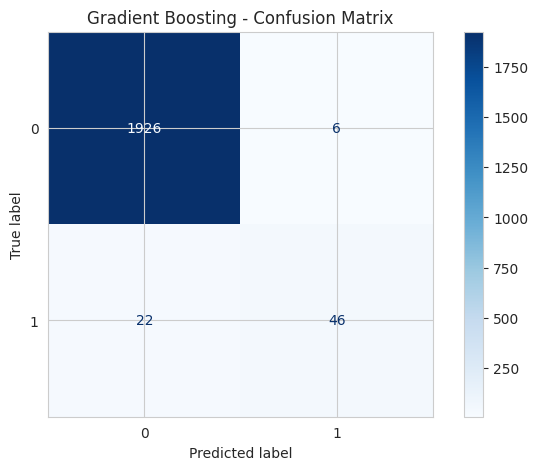

In [152]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    gb_pred,
    cmap="Blues"
)

plt.title("Gradient Boosting - Confusion Matrix")
plt.show()

In [153]:
from xgboost import XGBClassifier

In [154]:
X_train = X_train.rename(columns={
    'Air temperature [K]': 'Air_temperature_K',
    'Process temperature [K]': 'Process_temperature_K',
    'Rotational speed [rpm]': 'Rotational_speed_rpm',
    'Torque [Nm]': 'Torque_Nm',
    'Tool wear [min]': 'Tool_wear_min'
})

X_test = X_test.rename(columns={
    'Air temperature [K]': 'Air_temperature_K',
    'Process temperature [K]': 'Process_temperature_K',
    'Rotational speed [rpm]': 'Rotational_speed_rpm',
    'Torque [Nm]': 'Torque_Nm',
    'Tool wear [min]': 'Tool_wear_min'
})

X_train_scaled = X_train_scaled.rename(columns={
    'Air temperature [K]': 'Air_temperature_K',
    'Process temperature [K]': 'Process_temperature_K',
    'Rotational speed [rpm]': 'Rotational_speed_rpm',
    'Torque [Nm]': 'Torque_Nm',
    'Tool wear [min]': 'Tool_wear_min'
})

X_test_scaled = X_test_scaled.rename(columns={
    'Air temperature [K]': 'Air_temperature_K',
    'Process temperature [K]': 'Process_temperature_K',
    'Rotational speed [rpm]': 'Rotational_speed_rpm',
    'Torque [Nm]': 'Torque_Nm',
    'Tool wear [min]': 'Tool_wear_min'
})

In [155]:
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

xgb_metrics, xgb_pred = evaluate_model(
    xgb_model,
    X_train,
    X_test,
    y_train,
    y_test
)

pd.DataFrame(xgb_metrics, index=["XGBoost"])

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
XGBoost,0.9875,0.890909,0.720588,0.796748,0.972879


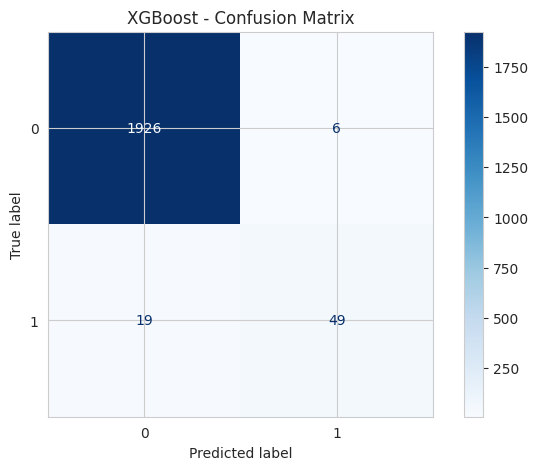

In [156]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_pred,
    cmap="Blues"
)

plt.title("XGBoost - Confusion Matrix")
plt.show()

### Observation

- XGBoost achieved the best overall performance among all evaluated models.
- The model correctly identified **49 out of 68** machine failures while generating only **6 false positives**, resulting in excellent classification performance.
- It achieved the highest **Accuracy (98.75%)**, **Precision (89.09%)**, **Recall (72.06%)**, **F1-score (79.67%)**, and **ROC-AUC (97.29%)**.
- Compared with the other models, XGBoost demonstrated the best balance between detecting machine failures and minimizing false alarms.
- Based on these evaluation metrics, XGBoost was selected as the final model for the predictive maintenance system.

In [157]:
model_comparison = pd.DataFrame(
    [
        log_metrics,
        dt_metrics,
        rf_metrics,
        gb_metrics,
        xgb_metrics
    ],
    index=[
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ]
)

model_comparison  = model_comparison.round(4)

model_comparison

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.8245,0.1418,0.8235,0.2419,0.9069
Decision Tree,0.9780,0.6818,0.6618,0.6716,0.8254
Random Forest,0.9815,0.8780,0.5294,0.6606,0.9616
Gradient Boosting,0.9860,0.8846,0.6765,0.7667,0.9698
XGBoost,0.9875,0.8909,0.7206,0.7967,0.9729


In [158]:
model_comparison .sort_values(
    by="F1-Score",
    ascending=False
)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
XGBoost,0.9875,0.8909,0.7206,0.7967,0.9729
Gradient Boosting,0.9860,0.8846,0.6765,0.7667,0.9698
Decision Tree,0.9780,0.6818,0.6618,0.6716,0.8254
Random Forest,0.9815,0.8780,0.5294,0.6606,0.9616
Logistic Regression,0.8245,0.1418,0.8235,0.2419,0.9069


# 6. Model Comparison

Five classification models were trained and evaluated for machine failure prediction.

Among all evaluated models, **XGBoost** achieved the best overall performance with:

- Accuracy: **98.75%**
- Precision: **89.09%**
- Recall: **72.06%**
- F1-score: **79.67%**
- ROC-AUC: **97.29%**

Although Logistic Regression achieved a higher Recall after applying class balancing, it suffered from very low Precision, producing many false alarms. Decision Tree, Random Forest, and Gradient Boosting significantly improved the balance between Precision and Recall.

Overall, XGBoost provided the best trade-off between correctly identifying machine failures and minimizing false positives, making it the most suitable model for predictive maintenance in this project.

# 7. Feature Importance

Feature importance analysis helps identify which input variables contributed the most to the model's predictions.

Understanding important features improves model interpretability and provides valuable insights into the operational factors associated with machine failures.

In [159]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
3,Torque_Nm,0.287685
0,Air_temperature_K,0.164432
4,Tool_wear_min,0.152136
1,Process_temperature_K,0.112285
2,Rotational_speed_rpm,0.107138
6,Type_M,0.102730
5,Type_L,0.073594


### Feature Importance

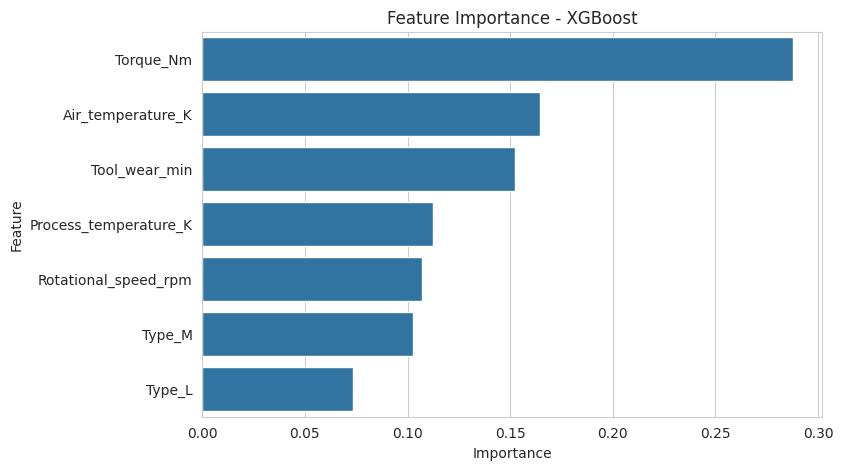

In [160]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - XGBoost")

plt.show()

### Observation

The XGBoost feature importance analysis indicates that **Torque** is the most influential feature for predicting machine failures, contributing approximately **28.8%** of the overall importance.

The next most important features are **Air Temperature** and **Tool Wear**, followed by **Process Temperature** and **Rotational Speed**. These variables collectively represent the operational condition of the machine and significantly influence the prediction of machine failures.

The encoded machine type features (**Type_M** and **Type_L**) contribute comparatively less to the prediction, suggesting that operational sensor measurements are more informative than machine category.

Overall, the feature importance analysis demonstrates that mechanical load (Torque), thermal conditions, and equipment wear are the primary factors influencing machine failure prediction.

In [161]:
import joblib

joblib.dump(xgb_model, "xgboost_predictive_maintenance.pkl")

print("Model saved successfully.")

loaded_model = joblib.load("xgboost_predictive_maintenance.pkl")

sample = X_test.iloc[:5]
predictions = loaded_model.predict(sample)

print("Predictions:", predictions)

Model saved successfully.
Predictions: [0 0 0 0 0]


# 8. Hyperparameter Tuning

The best-performing model (XGBoost) was further optimized using Randomized Search Cross Validation to identify better hyperparameter combinations and improve generalization performance.

In [162]:
from sklearn.model_selection import RandomizedSearchCV
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 3, 5]
}

In [163]:
random_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    ),
    param_distributions=param_dist,
    n_iter=20,
    scoring='f1',
    cv=5,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric='logloss',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_const...
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.8, 1.0],
                                        'learning_rate': [0.01, 0.05, 0.1],
                                        'max_depth': [3, 4, 5, 6],
                                        'min_child_weight': [1, 3, 5],
                                        'n_estimators': [100, 200, 300],
                                        'subsample': [0.8, 1.0]},
                   random_state=42, scoring='f1')

In [164]:
pd.DataFrame(
    random_search.best_params_.items(),
    columns=["Parameter","Best Value"]
)

,Parameter,Best Value
0,subsample,0.8
1,n_estimators,100.0
2,min_child_weight,1.0
3,max_depth,6.0
4,learning_rate,0.1
5,colsample_bytree,1.0


In [165]:
best_xgb = random_search.best_estimator_

best_metrics, best_pred = evaluate_model(
    best_xgb,
    X_train,
    X_test,
    y_train,
    y_test
)

pd.DataFrame(best_metrics,index=['Tuned XGBoost'])

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Tuned XGBoost,0.9875,0.921569,0.691176,0.789916,0.971349


# 9. Model Persistence

The final XGBoost model is saved using Joblib so that it can be reused for future predictions without retraining.

The saved model is then loaded and tested on unseen data to verify that it produces consistent predictions.

In [166]:
import joblib

joblib.dump(xgb_model, "predictive_maintenance_xgboost.pkl")

print("Model saved successfully!")

Model saved successfully!


In [167]:
loaded_model = joblib.load("predictive_maintenance_xgboost.pkl")

predictions = loaded_model.predict(X_test.iloc[:5])

print("Predictions:", predictions)

Predictions: [0 0 0 0 0]


## Prediction Example

The saved model is loaded and used to predict machine failures for unseen test samples. The table below compares the actual labels with the predicted labels.

In [168]:
prediction_results = X_test.iloc[:5].copy()

prediction_results["Actual"] = y_test.iloc[:5].values
prediction_results["Predicted"] = predictions

prediction_results

,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Type_L,Type_M,Actual,Predicted
2997,300.5,309.8,1345,62.7,153,1,0,0,0
4871,303.7,312.4,1513,40.1,135,1,0,0,0
3858,302.5,311.4,1559,37.6,209,1,0,0,0
951,295.6,306.3,1509,35.8,60,0,0,0,0
6463,300.5,310.0,1358,60.4,102,0,0,0,0


# 10. Project Conclusion

This project developed an end-to-end machine learning pipeline for predicting industrial machine failures using the AI4I 2020 Predictive Maintenance Dataset.

The workflow included:

- Dataset understanding
- Exploratory data analysis
- Data preprocessing
- Feature engineering
- Training and evaluating five classification models
- Feature importance analysis using XGBoost

Among all evaluated models, **XGBoost** achieved the best overall performance with:

- Accuracy: **98.75%**
- Precision: **89.09%**
- Recall: **72.06%**
- F1-score: **79.67%**
- ROC-AUC: **97.29%**

Feature importance analysis identified **Torque**, **Air Temperature**, and **Tool Wear** as the most influential factors in predicting machine failures.

The results demonstrate that machine learning techniques, particularly ensemble methods such as XGBoost, can effectively support predictive maintenance by identifying potential equipment failures before they occur.

# References

1. AI4I 2020 Predictive Maintenance Dataset
2. Scikit-learn Documentation
3. XGBoost Documentation
4. Pandas Documentation
5. NumPy Documentation
6. Matplotlib Documentation
7. Seaborn Documentation